# BÀI KIỂM TRA 1: CHUẨN BỊ DỮ LIỆU VÀ PIPELINE TIỀN XỬ LÝ
**Học phần:** Học máy (Machine Learning)  
**Notebook tiếp nối:** `02_chuan_bi_du_lieu.ipynb` (kế thừa bảng dữ liệu theo giờ từ `01_eda.ipynb`)

---

## 1. Phát biểu bài toán, Mục tiêu

### 1.1 Khung bài toán học máy
* **Bài toán:** Hồi quy chuỗi thời gian đơn biến/đa biến dự báo điện năng tiêu thụ theo giờ $y(t+h)$ ($\text{kWh}$) từ chuỗi quan sát quá khứ $\le t$.
* **Tầm dự báo cấu hình mặc định:** $h = 1$ giờ.
* **Nguyên tắc vàng ngăn chặn rò rỉ dữ liệu (Data Leakage):**
  1. **Chia tập theo thời gian:** Phân chia Train/Test theo mốc `target_time` ($t+h$), tuyệt đối **không xáo trộn ngẫu nhiên** (`shuffle=False`).
  2. **Kiểm định chéo theo thời gian:** Áp dụng `TimeSeriesSplit` có khoảng đệm đệm bảo vệ (`gap = 168` giờ).
  3. **Độc lập tham số:** Mọi bước học tham số (giá trị điền khuyết `SimpleImputer`, trung bình và độ lệch chuẩn `StandardScaler`, danh mục mã hóa `OneHotEncoder`) **chỉ được `fit` trên tập Train**, tập Test chỉ thực hiện `transform`.


## 2. Thiết lập Môi trường và Thư viện


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
                     "axes.labelsize": 10, "figure.dpi": 120})
HOURLY_PARQUET = Path("../data/processed/hourly.parquet")

## 3. Ô tham số cấu hình tập trung

Ô tham số này được đặt ở đầu notebook để sinh viên có thể thay đổi nhanh các cấu hình trong buổi vấn đáp (dưới 1 phút):
* Thay đổi chiến lược điền khuyết `IMPUTE_STRATEGY` (`"median"`, `"mean"`, `"most_frequent"`).
* Thay đổi tầm dự báo `H` hoặc mốc chia `TEST_START`.
* Thay đổi cột theo dõi thống kê `STAT_COLUMN`.


In [2]:
# Ô THAM SỐ. Ngưỡng giờ hợp lệ THRESH nằm ở 01_eda.ipynb vì hourly.parquet được tạo ở đó.
H = 1 # Tầm dự báo (giờ)
IMPUTE_STRATEGY = "median" # Chiến lược điền khuyết: "median", "mean", "most_frequent"
TEST_START = "2010-01-01" # Mốc chia Train / Test (theo thời điểm MỤC TIÊU)
N_SPLITS, TEST_SIZE, GAP = 5, 24 * 90, 168 # TimeSeriesSplit: số fold, kích thước validation (90 ngày), khoảng đệm (1 tuần)
STAT_COLUMN = "lag_0" # Cột để thống kê / vẽ nhanh khi vấn đáp

print(f"Cấu hình: H={H}h | điền khuyết={IMPUTE_STRATEGY} | Test từ {TEST_START} | "
      f"TimeSeriesSplit: {N_SPLITS} fold, test_size={TEST_SIZE}, gap={GAP}")

Cấu hình: H=1h | điền khuyết=median | Test từ 2010-01-01 | TimeSeriesSplit: 5 fold, test_size=2160, gap=168


## 4. Xây dựng Bảng Đặc trưng Học máy Có giám sát (Supervised Learning Table)

### 4.1 Quy tắc xây dựng đặc trưng cho tầm dự báo $h$
Mỗi mẫu dữ liệu tương ứng với một mốc thời gian gốc $t$, dùng để dự báo cho thời điểm mục tiêu $t+h$:
1. **Đặc trưng độ trễ (Lags):** Các giá trị trong quá khứ $\le t$ của chuỗi điện năng:
   - `lag_0`: Mức tiêu thụ tại giờ hiện tại $t$ ($y_t$).
   - `lag_1`: Mức tiêu thụ 1 giờ trước $t-1$ ($y_{t-1}$).
   - `lag_5`: Mức tiêu thụ 5 giờ trước $t-5$ ($y_{t-5}$).
   - `lag_23`: Mức tiêu thụ tại $t-23$ (tương ứng cùng giờ hôm trước so với $t+1$ khi $h=1$).
   - `lag_167`: Mức tiêu thụ tại $t-167$ (tương ứng cùng giờ tuần trước so với $t+1$ khi $h=1$).
2. **Đặc trưng lịch (Calendar):** Giờ trong ngày (`hour`) được trích xuất tại **thời điểm mục tiêu $t+h$** (vì thời điểm tương lai dự báo là thông tin lịch đã biết trước).
3. **Nhãn mục tiêu (Target):** $y_{t+h}$ được tạo bằng phép dịch `energy_hourly.shift(-h)`.


In [3]:
assert HOURLY_PARQUET.exists(), f"Không tìm thấy {HOURLY_PARQUET}. Hãy chạy 01_eda.ipynb trước!"
energy = pd.read_parquet(HOURLY_PARQUET)["energy_kwh"]

df_supervised = pd.DataFrame({f"lag_{k}": energy.shift(k) for k in (0, 1, 5, 23, 167)}) # đặc trưng trễ (<= t)
df_supervised["target_time"] = energy.index + pd.Timedelta(hours=H) # thời điểm mục tiêu t + H
df_supervised["hour"] = df_supervised["target_time"].dt.hour # lịch của thời điểm MỤC TIÊU
df_supervised["target"] = energy.shift(-H) # nhãn y(t + H)

print("BẢNG ĐẶC TRƯNG CÓ GIÁM SÁT (SUPERVISED LEARNING TABLE)")
print(f"Tổng số dòng theo lưới thời gian: {len(df_supervised):,} | Số mẫu có nhãn hợp lệ: {df_supervised['target'].notna().sum():,}")
display(df_supervised.head(8))

BẢNG ĐẶC TRƯNG CÓ GIÁM SÁT (SUPERVISED LEARNING TABLE)
Tổng số dòng theo lưới thời gian: 34,589 | Số mẫu có nhãn hợp lệ: 34,143


,lag_0,lag_1,lag_5,lag_23,lag_167,target_time,hour,target
timestamp,,,,,,,,
2006-12-16 17:00:00,NaN,NaN,NaN,NaN,NaN,2006-12-16 18:00:00,18,3.632200
2006-12-16 18:00:00,3.632200,NaN,NaN,NaN,NaN,2006-12-16 19:00:00,19,3.400233
2006-12-16 19:00:00,3.400233,3.632200,NaN,NaN,NaN,2006-12-16 20:00:00,20,3.268567
2006-12-16 20:00:00,3.268567,3.400233,NaN,NaN,NaN,2006-12-16 21:00:00,21,3.056467
2006-12-16 21:00:00,3.056467,3.268567,NaN,NaN,NaN,2006-12-16 22:00:00,22,2.200133
2006-12-16 22:00:00,2.200133,3.056467,NaN,NaN,NaN,2006-12-16 23:00:00,23,2.061600
2006-12-16 23:00:00,2.061600,2.200133,3.632200,NaN,NaN,2006-12-17 00:00:00,0,1.882467
2006-12-17 00:00:00,1.882467,2.061600,3.400233,NaN,NaN,2006-12-17 01:00:00,1,3.349400


## 5. Phân chia Train / Test theo Thời gian (Time-based Split)

### 5.1 Nguyên tắc phân chia
* Phân chia dựa trên **thời điểm mục tiêu** `target_time < TEST_START` cho tập Train và `target_time >= TEST_START` cho tập Test. Điều này đảm bảo tuyệt đối không có mẫu Train nào có nhãn rơi vào năm 2010.
* **Không xáo trộn dữ liệu (`shuffle=False`):** Chuỗi thời gian mang tính tự tương quan cao; việc xáo trộn ngẫu nhiên sẽ làm mô hình học từ tương lai để dự báo quá khứ (vi phạm giả định độc lập và gây rò rỉ dữ liệu).
* Các mẫu có nhãn `NaN` được giữ trong bảng dữ liệu tổng thể để đảm bảo lưới thời gian liên tục, nhưng được loại bỏ khi huấn luyện và đánh giá.


In [4]:
feature_cols = ["hour", "lag_0", "lag_1", "lag_5", "lag_23", "lag_167"]
has_label = df_supervised["target"].notna()
is_train = df_supervised["target_time"] < TEST_START      # chia theo thời điểm MỤC TIÊU, không xáo trộn

train_table, test_table = df_supervised[is_train & has_label], df_supervised[~is_train & has_label]
X_train, y_train = train_table[feature_cols], train_table["target"]
X_test, y_test = test_table[feature_cols], test_table["target"]

print("KÍCH THƯỚC VÀ THỜI GIAN CÁC TẬP DỮ LIỆU")
for name, table in (("TRAIN", train_table), ("TEST ", test_table)):
    print(f"Tập {name}: {len(table):,} mẫu có nhãn | thời gian mục tiêu: {table['target_time'].min()} -> {table['target_time'].max()}")
n_total = len(X_train) + len(X_test)
print(f"Tỷ lệ phân chia: Train {len(X_train) / n_total:.1%} | Test {len(X_test) / n_total:.1%}")

KÍCH THƯỚC VÀ THỜI GIAN CÁC TẬP DỮ LIỆU
Tập TRAIN: 26,523 mẫu có nhãn | thời gian mục tiêu: 2006-12-16 18:00:00 -> 2009-12-31 23:00:00
Tập TEST : 7,620 mẫu có nhãn | thời gian mục tiêu: 2010-01-01 00:00:00 -> 2010-11-26 20:00:00
Tỷ lệ phân chia: Train 77.7% | Test 22.3%


## 6. Kiểm định chéo theo Thời gian trên tập Train (TimeSeriesSplit)

### 6.1 Cơ chế cửa sổ mở rộng và Khoảng đệm an toàn (`gap = 168`)
* `TimeSeriesSplit` duy trì nguyên tắc nhân quả: Tập huấn luyện ở quá khứ, tập kiểm định (Validation) ở tương lai liền kề.
* Cửa sổ huấn luyện được **mở rộng dần (Expanding Window)** qua 5 fold, mô phỏng đúng quy trình hệ thống học máy tích lũy thêm dữ liệu mới trong thực tế.
* Tham số `gap = 168` giờ (1 tuần) đóng vai trò là **khoảng đệm an toàn**:
  1. Ngăn chặn sự chồng lấn giữa nhãn của mẫu huấn luyện cuối cùng với mẫu kiểm định đầu tiên.
  2. Bằng đúng độ dài của đặc trưng trễ dài nhất (`lag_167`), loại bỏ hoàn toàn nguy cơ rò rỉ chu kỳ tuần.


BẢNG CHI TIẾT CÁC FOLD KIỂM ĐỊNH CHÉO (TIMESERIESSPLIT)


,Fold,So_mau_Train,Train_Start,Train_End,So_mau_Val,Val_Start,Val_End
0,Fold 1,15555,2006-12-16,2008-09-27,2160,2008-10-04,2009-01-02
1,Fold 2,17715,2006-12-16,2008-12-26,2160,2009-01-02,2009-04-03
2,Fold 3,19875,2006-12-16,2009-03-27,2160,2009-04-03,2009-07-04
3,Fold 4,22035,2006-12-16,2009-06-27,2160,2009-07-04,2009-10-02
4,Fold 5,24195,2006-12-16,2009-09-25,2160,2009-10-03,2009-12-31


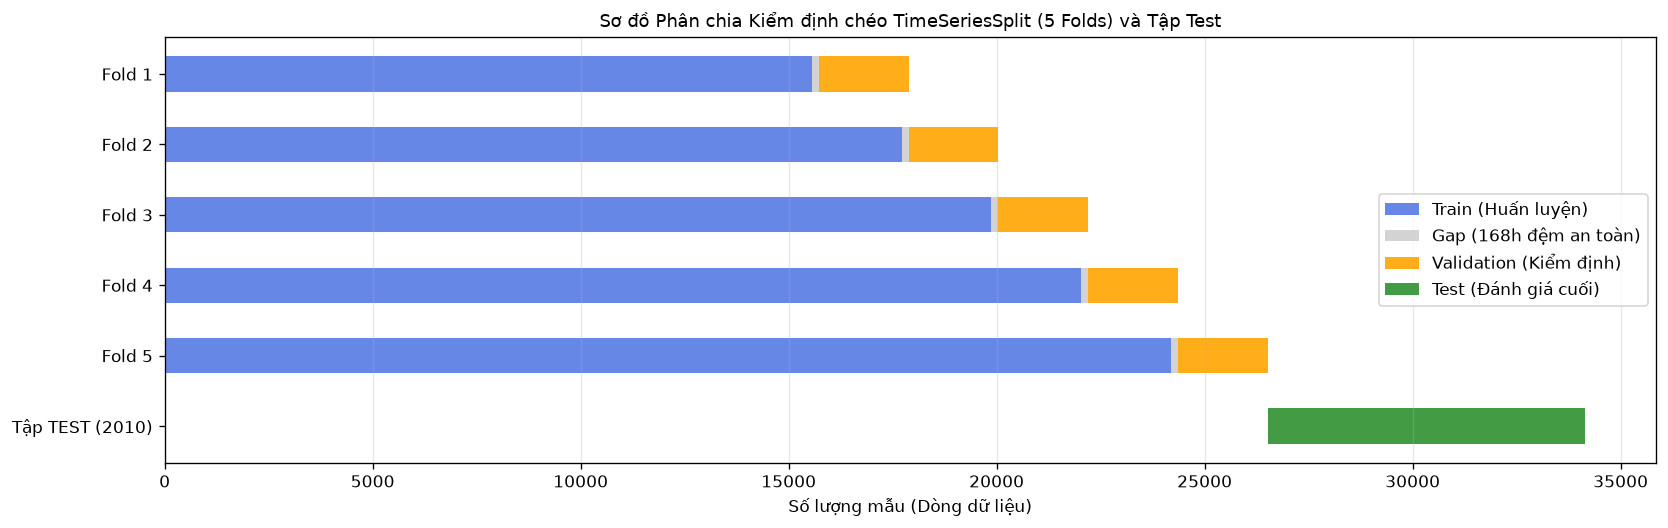

In [5]:
splits = list(TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, gap=GAP).split(X_train))
times = train_table["target_time"]

fold_table = pd.DataFrame([{
    "Fold": f"Fold {k}",
    "So_mau_Train": len(tr), "Train_Start": times.iloc[tr].min().date(), "Train_End": times.iloc[tr].max().date(),
    "So_mau_Val": len(val), "Val_Start": times.iloc[val].min().date(), "Val_End": times.iloc[val].max().date(),
} for k, (tr, val) in enumerate(splits, start=1)])
print("BẢNG CHI TIẾT CÁC FOLD KIỂM ĐỊNH CHÉO (TIMESERIESSPLIT)")
display(fold_table)

# Sơ đồ phân chia: mỗi dòng là một fold (Train -> Gap -> Validation), dòng cuối là tập Test
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, (tr, val) in enumerate(splits):
    first = k == 0   # chỉ ghi chú legend ở fold đầu
    ax.barh(k, len(tr), color="royalblue", alpha=0.8, height=0.5, label="Train (Huấn luyện)" if first else "")
    ax.barh(k, GAP, left=len(tr), color="lightgray", height=0.5, label=f"Gap ({GAP}h đệm an toàn)" if first else "")
    ax.barh(k, len(val), left=len(tr) + GAP, color="orange", alpha=0.9, height=0.5, label="Validation (Kiểm định)" if first else "")
ax.barh(N_SPLITS, len(X_test), left=len(X_train), color="forestgreen", alpha=0.85, height=0.5, label="Test (Đánh giá cuối)")
ax.set_yticks(range(N_SPLITS + 1), [f"Fold {k + 1}" for k in range(N_SPLITS)] + ["Tập TEST (2010)"])
ax.set(xlabel="Số lượng mẫu (Dòng dữ liệu)", title=f"Sơ đồ Phân chia Kiểm định chéo TimeSeriesSplit ({N_SPLITS} Folds) và Tập Test")
ax.invert_yaxis() # Fold 1 ở trên cùng, tập Test ở dưới cùng
ax.legend(loc="center right") # vùng bên phải còn trống, không che các thanh
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## 7. Xây dựng pipeline tiền xử lý với Cam kết Fit Chỉ trên Train

### 7.1 Cấu trúc `ColumnTransformer`
Quy trình tiền xử lý phân nhánh theo loại đặc trưng:
1. **Đặc trưng phân loại (`hour`):** Mã hóa `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` để giải quyết quan hệ phi tuyến giữa các giờ trong ngày mà không gây bùng nổ chiều đặc trưng.
2. **Đặc trưng định lượng (`numeric_lags`):**
   - Bước 1: `SimpleImputer(strategy=IMPUTE_STRATEGY)` điền các giá trị thiếu bằng giá trị trung vị (`median`) học được từ tập Train.
   - Bước 2: `StandardScaler()` chuẩn hóa dữ liệu về trung bình $\approx 0$ và độ lệch chuẩn $\approx 1$.
3. **Nguyên tắc bất biến:** `preprocessor.fit(X_train)` được gọi **duy nhất một lần trên tập Train**. Tập Test chỉ được gọi `preprocessor.transform(X_test)`.


In [6]:
cat_features = ["hour"]
num_features = ["lag_0", "lag_1", "lag_5", "lag_23", "lag_167"]

# One-hot cho biến phân loại; điền khuyết -> chuẩn hóa cho biến số
def make_preprocessor(strategy=IMPUTE_STRATEGY):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ("num", make_pipeline(SimpleImputer(strategy=strategy), StandardScaler()), num_features),
    ])


preprocessor = make_preprocessor().fit(X_train) # CHỈ fit trên tập Train
Z_train, Z_test = preprocessor.transform(X_train), preprocessor.transform(X_test)
n_ohe = len(preprocessor.named_transformers_["cat"].get_feature_names_out()) # các cột one-hot đứng trước các cột số trong Z

print("KẾT QUẢ THI CÔNG ĐƯỜNG ỐNG TIỀN XỬ LÝ (PIPELINE)")
print(f"X_train {X_train.shape} -> Z_train {Z_train.shape}")
print(f"X_test  {X_test.shape}  -> Z_test  {Z_test.shape}")

num_pipe = preprocessor.named_transformers_["num"]
df_learned_params = pd.DataFrame({
    "Dac_trung": num_features,
    f"Imputer_{IMPUTE_STRATEGY} (Train)": num_pipe["simpleimputer"].statistics_,
    "Scaler_Mean (Train)": num_pipe["standardscaler"].mean_,
    "Scaler_Scale_Std (Train)": num_pipe["standardscaler"].scale_,
}).round(4)
print("\nCÁC THAM SỐ THỐNG KÊ HỌC ĐƯỢC TỪ TẬP TRAIN")
display(df_learned_params)

KẾT QUẢ THI CÔNG ĐƯỜNG ỐNG TIỀN XỬ LÝ (PIPELINE)
X_train (26523, 6) -> Z_train (26523, 29)
X_test  (7620, 6)  -> Z_test  (7620, 29)

CÁC THAM SỐ THỐNG KÊ HỌC ĐƯỢC TỪ TẬP TRAIN


,Dac_trung,Imputer_median (Train),Scaler_Mean (Train),Scaler_Scale_Std (Train)
0,lag_0,0.7939,1.1002,0.9278
1,lag_1,0.7935,1.0999,0.9277
2,lag_5,0.7936,1.0999,0.9274
3,lag_23,0.7950,1.0994,0.9264
4,lag_167,0.7902,1.0944,0.9228


## 8. Bảng So sánh và Kiểm chứng Trước – Sau Tiền xử lý

### 8.1 Kiểm chứng mức độ làm sạch NaN và Tính đúng đắn của Chuẩn hóa
* Số lượng `NaN` trên cả tập Train và Test phải giảm về đúng **0** sau bước Imputer.
* Trên tập Train, trung bình của các đặc trưng số học sau chuẩn hóa phải $\approx 0$ và phương sai $\approx 1$.
* Trên tập Test, do áp dụng tham số học từ Train nên trung bình và độ lệch chuẩn sẽ hơi khác 0 và 1 (phản ánh đúng bản chất phân phối tự nhiên của dữ liệu tương lai).


KIỂM CHỨNG LÀM SẠCH GIÁ TRỊ KHUYẾT THIẾU (NaN)


,Dac_trung,Train_NaN_Truoc,Train_NaN_Sau,Test_NaN_Truoc,Test_NaN_Sau
0,lag_0,11,0,4,0
1,lag_1,19,0,8,0
2,lag_5,37,0,24,0
3,lag_23,100,0,96,0
4,lag_167,315,0,297,0



KIỂM CHỨNG PHÂN PHỐI SAU CHUẨN HÓA (STANDARDSCALER)


,Dac_trung,Train_Mean_Sau,Train_Std_Sau,Test_Mean_Sau,Test_Std_Sau
0,lag_0,0.0,1.0,-0.0426,0.8424
1,lag_1,0.0,1.0,-0.0422,0.8423
2,lag_5,0.0,1.0,-0.0419,0.8432
3,lag_23,0.0,1.0,-0.0441,0.8418
4,lag_167,-0.0,1.0,-0.0291,0.8395


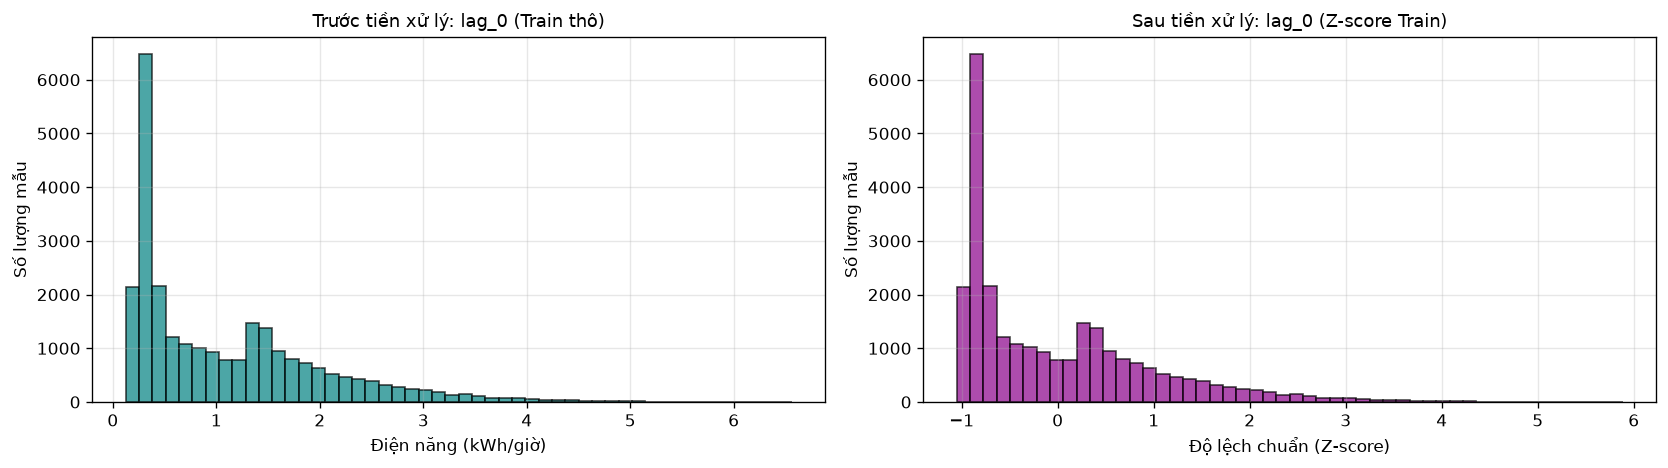

In [7]:
Zn_train, Zn_test = Z_train[:, n_ohe:], Z_test[:, n_ohe:] # chỉ các cột số (đã điền khuyết + chuẩn hóa)

df_nan_check = pd.DataFrame({
    "Dac_trung": num_features,
    "Train_NaN_Truoc": X_train[num_features].isna().sum().values, "Train_NaN_Sau": np.isnan(Zn_train).sum(axis=0),
    "Test_NaN_Truoc": X_test[num_features].isna().sum().values, "Test_NaN_Sau": np.isnan(Zn_test).sum(axis=0),
})
print("KIỂM CHỨNG LÀM SẠCH GIÁ TRỊ KHUYẾT THIẾU (NaN)")
display(df_nan_check)

df_scale_check = pd.DataFrame({
    "Dac_trung": num_features,
    "Train_Mean_Sau": Zn_train.mean(axis=0), "Train_Std_Sau": Zn_train.std(axis=0),
    "Test_Mean_Sau": Zn_test.mean(axis=0), "Test_Std_Sau": Zn_test.std(axis=0),
}).round(4)
print("\nKIỂM CHỨNG PHÂN PHỐI SAU CHUẨN HÓA (STANDARDSCALER)")
display(df_scale_check)

# Phân bố STAT_COLUMN trước và sau chuẩn hóa
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(14, 4))
ax_before.hist(X_train[STAT_COLUMN].dropna(), bins=50, color="teal", edgecolor="black", alpha=0.7)
ax_after.hist(Zn_train[:, num_features.index(STAT_COLUMN)], bins=50, color="darkmagenta", edgecolor="black", alpha=0.7)
for ax, title, xlabel in ((ax_before, f"Trước tiền xử lý: {STAT_COLUMN} (Train thô)", "Điện năng (kWh/giờ)"),
                          (ax_after, f"Sau tiền xử lý: {STAT_COLUMN} (Z-score Train)", "Độ lệch chuẩn (Z-score)")):
    ax.set(title=title, xlabel=xlabel, ylabel="Số lượng mẫu")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Thực nghiệm Chứng minh: "Fit trên toàn bộ dữ liệu là Rò rỉ thông tin"

Ta thực hiện so sánh đối chứng giữa hai phương thức học tham số:
1. **Phương thức chuẩn mực (Không rò rỉ):** Fit bộ biến đổi chỉ trên tập Train.
2. **Phương thức sai phạm (Rò rỉ dữ liệu - Data Leakage):** Fit bộ biến đổi trên toàn bộ dữ liệu (Train + Test gộp chung).


In [8]:
# So sánh: fit scaler chỉ trên Train (đúng) với fit trên Train + Test gộp chung (rò rỉ)
scaler_correct = StandardScaler().fit(X_train[num_features])
scaler_leaked = StandardScaler().fit(pd.concat([X_train[num_features], X_test[num_features]]))

df_leakage_comparison = pd.DataFrame({
    "Dac_trung": num_features,
    "Mean_Chuan (Chi Fit Train)": scaler_correct.mean_, "Mean_Ro_ri (Fit Toan Bo)": scaler_leaked.mean_,
    "Chenh_lech_Mean": scaler_leaked.mean_ - scaler_correct.mean_,
    "Std_Chuan (Chi Fit Train)": scaler_correct.scale_, "Std_Ro_ri (Fit Toan Bo)": scaler_leaked.scale_,
    "Chenh_lech_Std": scaler_leaked.scale_ - scaler_correct.scale_,
}).round(4)

print("ĐỊNH LƯỢNG SAI LỆCH THAM SỐ DO HIỆN TƯỢNG RÒ RỈ DỮ LIỆU (DATA LEAKAGE)")
display(df_leakage_comparison)

ĐỊNH LƯỢNG SAI LỆCH THAM SỐ DO HIỆN TƯỢNG RÒ RỈ DỮ LIỆU (DATA LEAKAGE)


,Dac_trung,Mean_Chuan (Chi Fit Train),Mean_Ro_ri (Fit Toan Bo),Chenh_lech_Mean,Std_Chuan (Chi Fit Train),Std_Ro_ri (Fit Toan Bo),Chenh_lech_Std
0,lag_0,1.1004,1.0916,-0.0088,0.9280,0.8976,-0.0304
1,lag_1,1.1001,1.0914,-0.0087,0.9280,0.8975,-0.0304
2,lag_5,1.1003,1.0917,-0.0086,0.9280,0.8978,-0.0301
3,lag_23,1.1005,1.0920,-0.0086,0.9280,0.8983,-0.0297
4,lag_167,1.0981,1.0938,-0.0042,0.9277,0.8991,-0.0286


> **Nhận xét chuyên sâu về rò rỉ dữ liệu:**
> * **Bản chất sai phạm:** Giá trị trung bình của `lag_0` trên tập Train chuẩn mực là **$1,1004\text{ kWh}$**, trong khi khi fit trên toàn bộ dữ liệu chỉ còn **$1,0916\text{ kWh}$** (chênh lệch $-0,0088\text{ kWh}$).
> * Mặc dù độ chênh lệch số học nhìn qua có vẻ nhỏ, nhưng về mặt bản chất phương pháp học máy:
>   - Việc fit trên toàn bộ dữ liệu đã để **thông tin về phân phối của năm 2010 (tập Test tương lai) lọt vào trọng số chuẩn hóa** của mô hình.
>   - Trong thực tế vận hành sản xuất, tại thời điểm mô hình triển khai, dữ liệu tương lai của năm sau hoàn toàn chưa xảy ra $\implies$ Mọi mô hình fit trên dữ liệu gộp đều là mô hình học máy vi phạm tính nhân quả và mang lại kết quả đánh giá lạc quan giả tạo.
> * Kết luận: Quy trình sử dụng `ColumnTransformer` đóng gói trong Pipeline và chỉ gọi `.fit()` trên `X_train` là lá chắn bảo vệ an toàn tuyệt đối chống lại mọi dạng rò rỉ dữ liệu.

## 10. Hàm Tiện ích thao tác nhanh

Sử dụng các khối mã dưới đây để thao tác theo yêu cầu tức thời của Giảng viên:
1. Đổi phương pháp điền khuyết sang `mean` hoặc `most_frequent` và in lại kết quả trong 10 giây.
2. Thống kê và trực quan hóa phân bố của một đặc trưng bất kỳ.


In [9]:
def thao_tac_doi_phuong_phap_dien_khuyet(new_strategy="mean"):
    pipe = make_preprocessor(new_strategy).fit(X_train)
    value = pipe.named_transformers_["num"]["simpleimputer"].statistics_[num_features.index(STAT_COLUMN)]
    print(f"--> Phương pháp '{new_strategy}': giá trị điền khuyết học từ Train cho '{STAT_COLUMN}' = {value:.4f}")
    return pipe


test_pipe_mean = thao_tac_doi_phuong_phap_dien_khuyet("mean")

--> Phương pháp 'mean': giá trị điền khuyết học từ Train cho 'lag_0' = 1.1004


## 11. Đặc trưng Cửa sổ trượt (Rolling Window)

### 11.1 Quy tắc xây dựng
* Thống kê trên $w$ giờ gần nhất **kết thúc tại thời điểm gốc $t$**: trung bình $\bar{y}^{(w)}_t = \frac{1}{w}\sum_{j=0}^{w-1} y_{t-j}$ với $w \in \{3, 24, 168\}$ và độ lệch chuẩn 24 giờ.
* `rolling(w)` của pandas mặc định lấy cửa sổ **kết thúc tại** dòng hiện tại nên chỉ dùng dữ liệu $\le t$. Cửa sổ cần ít nhất 75% số giờ có giá trị (`min_periods`), ngược lại là `NaN` và sẽ được điền khuyết trong Pipeline như các đặc trưng trễ.
* **Đối chứng rò rỉ:** cửa sổ **căn giữa** (`center=True`) dùng cả 12 giờ sau $t$ (gồm cả nhãn $y_{t+1}$), tức là nhìn thấy tương lai, nên tuyệt đối không được dùng.
* Các đặc trưng này được kiểm tra ở BKT1 và sẽ được đưa vào bộ đặc trưng của mô hình ở Tuần 6.

In [10]:
WINDOWS = (3, 24, 168)
df_rolling = pd.DataFrame({f"roll_mean_{w}": energy.rolling(w, min_periods=int(0.75 * w)).mean() for w in WINDOWS})
df_rolling["roll_std_24"] = energy.rolling(24, min_periods=18).std()
centered_24 = energy.rolling(24, min_periods=18, center=True).mean()       # SAI: nhìn thấy tương lai, chỉ để đối chứng

# Kiểm tra tính nhân quả: roll_mean_3 tại t phải bằng trung bình của y(t-2), y(t-1), y(t)
k = 1000
assert np.isclose(df_rolling["roll_mean_3"].iloc[k], energy.iloc[k - 2:k + 1].mean())
print("Kiểm tra nhân quả: roll_mean_3(t) = mean(y[t-2..t]) -> ĐÚNG")

# Tương quan Spearman với nhãn trên đúng các mẫu Train (cùng chỉ mục thời điểm gốc t)
check = df_rolling.loc[train_table.index].assign(lag_0=train_table["lag_0"], centered_24_SAI=centered_24.loc[train_table.index],
                                                  target=train_table["target"])
print(f"\nSố mẫu Train: {len(check):,} | Số NaN của từng đặc trưng: {df_rolling.loc[train_table.index].isna().sum().to_dict()}")
print(f"TƯƠNG QUAN SPEARMAN VỚI NHÃN (TRAIN, h = {H})")
display(check.corr(method="spearman")["target"].drop("target").round(3).to_frame("Spearman"))

Kiểm tra nhân quả: roll_mean_3(t) = mean(y[t-2..t]) -> ĐÚNG

Số mẫu Train: 26,523 | Số NaN của từng đặc trưng: {'roll_mean_3': 16, 'roll_mean_24': 72, 'roll_mean_168': 378, 'roll_std_24': 72}
TƯƠNG QUAN SPEARMAN VỚI NHÃN (TRAIN, h = 1)


,Spearman
roll_mean_3,0.607
roll_mean_24,0.386
roll_mean_168,0.361
roll_std_24,0.322
lag_0,0.764
centered_24_SAI,0.488


> **Nhận xét đặc trưng cửa sổ trượt:**
> * Kiểm tra nhân quả cho thấy cửa sổ kết thúc đúng tại $t$, không dùng dữ liệu tương lai.
> * Với $h = 1$, `roll_mean_3` có tương quan Spearman với nhãn là $0,607$, thấp hơn `lag_0` ($0,764$): giá trị giờ gần nhất vẫn là thông tin mạnh nhất ở tầm dự báo ngắn. `roll_mean_24` ($0,386$), `roll_mean_168` ($0,361$) và `roll_std_24` ($0,322$) mô tả **mức nền** và **độ biến động** gần đây; vai trò của chúng dự kiến lớn hơn ở tầm dự báo xa, khi `lag_0` mất dần tác dụng (Mục 8.2 của notebook 01).
> * Cửa sổ **căn giữa** cho tương quan $0,488$, cao hơn hẳn cửa sổ đúng `roll_mean_24` ($0,386$) chỉ vì nó chứa 12 giờ tương lai. Đây là minh họa định lượng cho rò rỉ qua đặc trưng: con số đẹp hơn nhưng không dùng được khi dự báo thật.